# Exercise 8.1.7: Training LISTA
In this exercise, we will train two versions of LISTA for sparse recovery of MNIST images.

## Change runtime type and install DeepInverse package
First, we install the deepinverse library. Remeber to change the runtime of this notebook select ``Runtime`` -> ``Change runtime type`` and pick an available hardware accelerator.

In [ ]:
!pip install git+https://github.com/deepinv/deepinv.git#egg=deepinv

  Cloning https://github.com/deepinv/deepinv.git to /tmp/pip-install-e1lcznm5/deepinv_1bad9b5c52884c469583ec31b815fd6e
  Running command git clone --filter=blob:none --quiet https://github.com/deepinv/deepinv.git /tmp/pip-install-e1lcznm5/deepinv_1bad9b5c52884c469583ec31b815fd6e
  Resolved https://github.com/deepinv/deepinv.git to commit f304b6adc964e0054fd182d1044c7af11d2d116a
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.1/44.1 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 77.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 64.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 41.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.7 MB/s eta 0:00:00
   ━━

In [2]:
import deepinv as dinv
from torch.utils.data import DataLoader
import torch
from pathlib import Path
from torchvision import transforms
from deepinv.utils.demo import load_dataset

import matplotlib.pyplot as plt

# Setup paths for data loading and checkpoints

In [3]:
BASE_DIR = Path(".")
DATA_DIR = BASE_DIR / "measurements"
CKPT_DIR = BASE_DIR / "ckpts"

# Set the global random seed from pytorch to ensure reproducibility of the example.
torch.manual_seed(0)

device = dinv.utils.get_freer_gpu() if torch.cuda.is_available() else "cpu"

Selected GPU 0 with 7876.4375 MiB free memory


# Load base image datasets and degradation operators
In this example, we use the MNIST dataset of $28 \times 28$ hand-written digits. It also contains labels for a classification task; we ignore them.

In [4]:
from torchvision import datasets

class MNIST_wrapper(datasets.MNIST):
    def __getitem__(self, index: int):
        """
        Args:
            index (int): Index

        Returns:
            tuple: (image, target) where target is index of the target class.
        """
        img = super(MNIST_wrapper, self).__getitem__(index) 
        
        
        # return torch.nn.functional.pad(img[0],(10,10,10,10)) # use this line to zero-pad borders of the image to make it even more sparse 
        return img[0] # return only image, without a label

operation = "compressed_sensing"

dataset_name = "MNIST"

img_size = 28
n_channels = 1

test_transform = transforms.Compose(
    [transforms.ToTensor()]
)

train_transform = transforms.Compose([
    transforms.ToTensor()]
)


dataset_name = "MNIST"
dataset_path = BASE_DIR / "datasets" / dataset_name
train_dataset = MNIST_wrapper(root=dataset_path, train=True, transform=train_transform, download=True)
test_dataset = MNIST_wrapper(root=dataset_path, train=False, transform=test_transform, download=True)

# Set up physics and pregenerate dataset
Define a physics object for [compression](https://deepinv.github.io/deepinv/api/stubs/deepinv.physics.CompressedSensing.html). Since a Gaussian matrix is dense and multiplication with it is slow, we pregenerate the measurements and store them as HDF5 files. 

See [this overview](https://deepinv.github.io/deepinv/auto_examples/physics/demo_physics_tour.html) and a [complete list](https://deepinv.github.io/deepinv/api/deepinv.physics.html) of physics models available at DeepInverse.

In [5]:
num_workers = 1 if torch.cuda.is_available() else 0

# Generate the compressed sensing measurement operator with 5x under-sampling factor.
physics = dinv.physics.CompressedSensing(
    m=157, img_size=(n_channels, img_size, img_size), fast=False, device=device
)
# This is a significantly undersampled scenario (See Ex 3.3 (ii)). You increase m to make FISTA more competative

my_dataset_name = "MNIST_compressed"

spec_norm = torch.linalg.matrix_norm(physics._A, 2)
print('Spectral norm: ', spec_norm)

n_images_max = (
    5000 if torch.cuda.is_available() else 200
)  

# maximal number of images used for training
measurement_dir = DATA_DIR / dataset_name / operation
generated_datasets_path = dinv.datasets.generate_dataset(
    train_dataset=train_dataset,
    test_dataset=test_dataset,
    physics=physics,
    device=device,
    save_dir=measurement_dir,
    train_datapoints=n_images_max,
    test_datapoints=8,
    num_workers=num_workers,
    dataset_filename=str(my_dataset_name),
    overwrite_existing = True,
)

# Now, we do the split for the training and validation datasets

train_dataset = dinv.datasets.HDF5Dataset(path=generated_datasets_path, train=True)
val_dataset = dinv.datasets.HDF5Dataset(path=generated_datasets_path, train=True)
test_dataset = dinv.datasets.HDF5Dataset(path=generated_datasets_path, train=False)

indices = torch.randperm(len(train_dataset))
val_size = 200 if torch.cuda.is_available() else 10
train_dataset = torch.utils.data.Subset(train_dataset, indices[:-val_size])
val_dataset = torch.utils.data.Subset(val_dataset, indices[-val_size:])

Spectral norm:  tensor(3.1986, device='cuda:0')


/homes/numerik/melnyk/scratch/anaconda3_new/lib/python3.13/site-packages/deepinv/datasets/datagenerator.py:344: UserWarning: Dataset measurements/MNIST/compressed_sensing/MNIST_compressed0.h5 already exists, this will close and overwrite the previous dataset.
  warn(


Dataset has been saved at measurements/MNIST/compressed_sensing/MNIST_compressed0.h5


# Plot an image from a dataset
Try plotting it multiple times! Note that our dataset now contains tuples (x_i, y_i) as we pregenerated it.

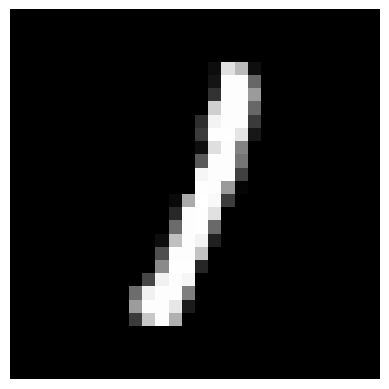

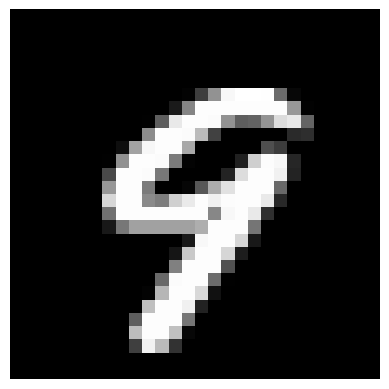

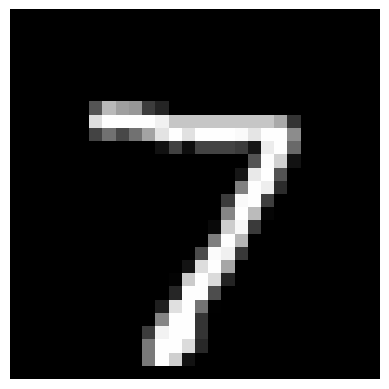

In [6]:
plt.imshow(train_dataset[0][0].permute(1, 2, 0),cmap = 'gray')
plt.axis("off")
plt.show()

plt.imshow(val_dataset[0][0].permute(1, 2, 0),cmap = 'gray')
plt.axis("off")
plt.show()

plt.imshow(test_dataset[0][0].permute(1, 2, 0),cmap = 'gray')
plt.axis("off")
plt.show()

# Prepare dataloaders
Dataloaders handle loading datasets into memory. You can set up the batchs size and whether you want the elements be randomly reschuffled, see Remark 5.3.4.

In [7]:
# n_channels = 3 
num_workers = 1 if torch.cuda.is_available() else 1

train_batch_size = 32 if torch.cuda.is_available() else 1
val_batch_size = 32 if torch.cuda.is_available() else 1
test_batch_size = 32 if torch.cuda.is_available() else 1

train_dataloader = DataLoader(
    train_dataset, batch_size=train_batch_size, num_workers=num_workers, shuffle=True
)

val_dataloader = DataLoader(
    val_dataset, batch_size=val_batch_size, num_workers=num_workers, shuffle=False
)

test_dataloader = DataLoader(
    test_dataset, batch_size=test_batch_size, num_workers=num_workers, shuffle=False
)

# Set up LISTA network

We set LISTA as two classes, the iteration class and the class that performs the reconstruction.

In [8]:
class LISTA_block(torch.nn.Module):
    r"""
    This class is for LISTA updates x^{k+1} = S_{\lambda^k}(W1 y + W2 x^k)
    
    :param int img_size: width of a square image.
    :param int m: Number of measurements.
    :param torch.Tensor (img_size**2 \times m) A: Forward operator.
    :param float spec_norm: Spectral norm of A.
    :param torch.device, str device: Device to put the model on.
    :param float alpha: Regularization parameter in 0.5 \|Ax - y\|_2^2 + \alpha \|x\|_1.
    """

    def __init__(
        self,
        img_size,
        m,
        A,
        spec_norm,
        device,
        alpha = 1.0,
    ):
        super(LISTA_block, self).__init__()

        self.n = img_size**2
        self.m = m

        # Initialize weights with as in ISTA
        nu = 1.0 / spec_norm**2
        self.W1 = torch.nn.Linear(self.m, self.n, bias = False, device = device)
        self.W1.weight.data = nu * A.transpose(0,1).clone()
        
        self.W2 = torch.nn.Linear(self.n, self.n, bias = False, device = device)
        self.W2.weight.data = (torch.eye(self.n).to(device) - nu * A.transpose(0,1).matmul(A) ).clone() 
        
        self.soft = torch.nn.Parameter(alpha * nu * torch.ones([1]).to(device))
        self.soft.requires_grad_(True)

        self.device = device
        
    def forward(self, x: torch.Tensor, y: torch.Tensor,
                **kwarg) -> torch.Tensor:
        r"""
        Apply single LISTA iteration.

        :param torch.Tensor x: Previous iterates of shape ``(B, img_size**2)``,
        :param torch.Tensor y: Measurements of shape ``(B, m)``.
        """
        # Apply stacked convolution layers
        z = self.W1(y)
        z = z.add(self.W2(x))
        
        # Soft thresholding
        signz = z.sign()
        z = z.abs() - self.soft
        z = torch.nn.functional.relu(z)
        z = signz * z

        return z

class LISTA(torch.nn.Module):
    def __init__(
        self,
        img_size,
        m,
        A,
        spec_norm,
        device,
        alpha = 1.0,
    ):
        r"""
        :param int img_size: width of a square image.
        :param int m: Number of measurements.
        :param torch.Tensor (img_size**2 \times m) A: Forward operator.
        :param float spec_norm: Spectral norm of A.
        :param torch.device, str device: Device to put the model on.
        :param float alpha: Regularization parameter in 0.5 \|Ax - y\|_2^2 + \alpha \|x\|_1.
        """
        
        super().__init__()

        self.iters = torch.nn.ModuleList(
            []
        )
        self.device = device
        self.img_size = img_size
        self.A = A
        self.m = m
        self.n = A.shape[1]
        self.spec_norm = spec_norm
        self.alpha = alpha

    def forward(self,y, physics, **kwarg):
        # Set up the initialization
        x = torch.zeros([y.shape[0], self.img_size**2]).to(device)

        # Apply the iterations
        for i, l in enumerate(self.iters):
            x = self.iters[i](x,y)

        # Reshape the output into images of shape (B, 1, img_size, img_size)
        x = x.reshape([y.shape[0], 1, self.img_size, self.img_size])
        return x

    def add_block(self):
        self.iters.append(LISTA_block(self.img_size, self.m, self.A, self.spec_norm, self.device, self.alpha))

# Set up a Trainer

Now, we set up the training procedure as described in the lecture notes. That is, in each iteration, we add a new layer and only optimize its parameters first. Then, we proceed to train all parameters together.

See https://deepinv.github.io/deepinv/user_guide/training/trainer.html#trainer
and https://deepinv.github.io/deepinv/api/stubs/deepinv.Trainer.html for more details.

In [9]:
def train_lista(LISTA_class, num_layers, lr_one, lr_whole, epochs_one, epochs_whole):
    lista = LISTA_class(img_size = img_size, m = physics._A.shape[0], A = physics._A, spec_norm = spec_norm, device = device)
    
    verbose = True  # print training information
    wandb_vis = False  # plot curves and images in Weight&Bias
    
    
    # learning_rate = lr
    weight_decay=1e-8
    
    # choose training losses
    losses = [dinv.loss.SupLoss(metric=dinv.metric.MSE())]
    
    # train the new block
    for i in range(num_layers):
        # Train only new block first
        lista.add_block()

        print('-------------------------------------------------')
        print('----------TRAINING ',i+1,' BLOCK-------------------')
        print('-------------------------------------------------')
        
        # choose optimizer and scheduler
        optimizer = torch.optim.Adam(lista.iters[i].parameters(), lr=lr_one, weight_decay = weight_decay)
        scheduler = torch.optim.lr_scheduler.StepLR(optimizer,step_size=epochs_one,gamma=0.99)
        trainer = dinv.Trainer(
            lista,
            device=device,
            save_path=str(CKPT_DIR / operation), 
            verbose=verbose,
            wandb_vis=False,
            physics=physics,
            epochs=epochs_one,
            scheduler=scheduler,
            losses=losses,
            optimizer=optimizer,
            show_progress_bar=False,  # disable progress bar for better vis in sphinx gallery.
            train_dataloader=train_dataloader,
            eval_dataloader=val_dataloader,
            plot_images=False, # You can plot images, to see the network's actual denoising. Significantly increases the size of the notebook.
            plot_measurements=False,
            online_measurements=False,  # Do our datasets contain both (x_i, y_i) or we want to generate y_i = physics(x_i) on the fly?
            no_learning_method = 'A_adjoint', # Baseline to compare with: options 'y', 'A_dagger', 'A_adjoint', 'prox_l2'
            ckp_interval = epochs_one-1, # Store network parameters every ckp_interval epochs. Very useful in practice.
        )
        print('--------Train perf. pre training----------')
        trainer.test(train_dataloader)
        trainer.train()
        lista = trainer.load_best_model()
        print('--------Train perf. post training----------')
        trainer.test(train_dataloader)
        print('--------Val perf. post training----------')
        trainer.test(val_dataloader)

        # Train whole lista
        print('-------------------------------------------------')
        print('----------TRAINING ALL ',i+1,' BLOCKS--------------')
        print('-------------------------------------------------')
        
        # optimizer = torch.optim.Adam(lista.parameters(), lr=lr_whole, weight_decay = weight_decay)
        # scheduler = torch.optim.lr_scheduler.StepLR(optimizer,step_size=epochs_whole,gamma=0.99)
        optimizer.parameters = lista.parameters()
        optimizer.lr = lr_whole
        scheduler.step_size = epochs_whole
        trainer = dinv.Trainer(
            lista,
            device=device,
            save_path=str(CKPT_DIR / operation), 
            verbose=verbose,
            wandb_vis=False,
            physics=physics,
            epochs=epochs_whole,
            scheduler=scheduler,
            losses=losses,
            optimizer=optimizer,
            show_progress_bar=False,  # disable progress bar for better vis in sphinx gallery.
            train_dataloader=train_dataloader,
            eval_dataloader=val_dataloader,
            plot_images=False, # You can plot images, to see the network's actual denoising. Significantly increases the size of the notebook.
            plot_measurements=False,
            online_measurements=False,  # Do our datasets contain both (x_i, y_i) or we want to generate y_i = physics(x_i) on the fly?
            no_learning_method = 'A_adjoint', # Baseline to compare with: options 'y', 'A_dagger', 'A_adjoint', 'prox_l2'
            ckp_interval = epochs_whole-1, # Store network parameters every ckp_interval epochs. Very useful in practice.
        )
        print('--------Train perf. pre training----------')
        trainer.test(train_dataloader)
        trainer.train()
        lista = trainer.load_best_model()
        print('--------Train perf. post training----------')
        trainer.test(train_dataloader)
        print('--------Val perf. post training----------')
        trainer.test(val_dataloader)

    trainer.plot_images = True
    trainer.test(test_dataloader)
    return lista

-------------------------------------------------
----------TRAINING  1  BLOCK-------------------
-------------------------------------------------
--------Train perf. pre training----------


/homes/numerik/melnyk/scratch/anaconda3_new/lib/python3.13/site-packages/deepinv/training/trainer.py:1544: UserWarning: non_blocking_transfers=True but DataLoader.pin_memory=False; set pin_memory=True to overlap host-device copies with compute.
  self.setup_train(train=False)


Eval epoch 0: PSNR=9.985, PSNR no learning=2.863
Test results:
PSNR no learning: 2.863 +- 1.719
PSNR: 9.985 +- 1.565
The model has 737745 trainable parameters


/homes/numerik/melnyk/scratch/anaconda3_new/lib/python3.13/site-packages/deepinv/training/trainer.py:1352: UserWarning: non_blocking_transfers=True but DataLoader.pin_memory=False; set pin_memory=True to overlap host-device copies with compute.
  self.setup_train()


Train epoch 0: TotalLoss=0.031, PSNR=15.734
Eval epoch 0: PSNR=18.314, PSNR no learning=3.317
Best model saved at epoch 1
Train epoch 1: TotalLoss=0.014, PSNR=18.905
Eval epoch 1: PSNR=19.925, PSNR no learning=3.317
Best model saved at epoch 2
Train epoch 2: TotalLoss=0.011, PSNR=20.126
Eval epoch 2: PSNR=20.844, PSNR no learning=3.317
Best model saved at epoch 3
Train epoch 3: TotalLoss=0.009, PSNR=20.881
Eval epoch 3: PSNR=21.458, PSNR no learning=3.317
Best model saved at epoch 4
Train epoch 4: TotalLoss=0.008, PSNR=21.4
Eval epoch 4: PSNR=21.885, PSNR no learning=3.317
Best model saved at epoch 5
Train epoch 5: TotalLoss=0.007, PSNR=21.78
Eval epoch 5: PSNR=22.219, PSNR no learning=3.317
Best model saved at epoch 6
Train epoch 6: TotalLoss=0.007, PSNR=22.07
Eval epoch 6: PSNR=22.474, PSNR no learning=3.317
Best model saved at epoch 7
Train epoch 7: TotalLoss=0.006, PSNR=22.301
Eval epoch 7: PSNR=22.656, PSNR no learning=3.317
Best model saved at epoch 8
Train epoch 8: TotalLoss=0.0

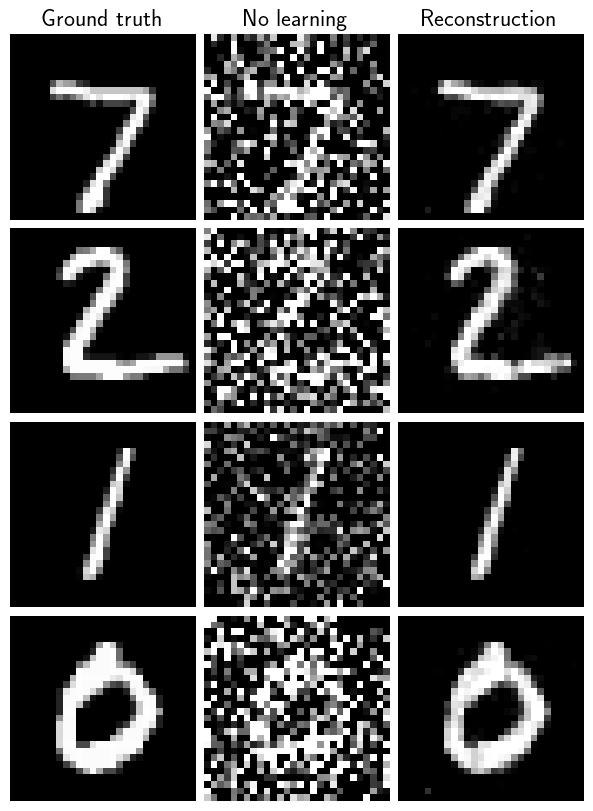

Test results:
PSNR no learning: 3.870 +- 1.864
PSNR: 28.395 +- 5.088


LISTA(
  (iters): ModuleList(
    (0-4): 5 x LISTA_block(
      (W1): Linear(in_features=157, out_features=784, bias=False)
      (W2): Linear(in_features=784, out_features=784, bias=False)
    )
  )
)

In [34]:
lista = train_lista(LISTA,5, 5e-4, 5e-3, 30, 30)
lista.eval()

# LISTA-CP

In [10]:
class LISTA_CP_block(torch.nn.Module):
    r"""
    This class is for LISTA-CP updates x^{k+1} = S_{\lambda^k}(x^k - W( Ax^k - y))
    
        :param int img_size: width of a square image.
        :param int m: Number of measurements.
        :param torch.Tensor (img_size**2 \times m) A: Forward operator.
        :param float spec_norm: Spectral norm of A.
        :param torch.device, str device: Device to put the model on.
        :param float alpha: Regularization parameter in 0.5 \|Ax - y\|_2^2 + \alpha \|x\|_1.
        """
    def __init__(
        self,
        img_size,
        m,
        A,
        spec_norm,
        device,
        alpha = 1.0,
    ):
        super(LISTA_CP_block, self).__init__()

        self.n = img_size**2
        self.m = m

        # Initialize weights with as in ISTA
        nu = 1.0 / spec_norm**2
        self.W = torch.nn.Linear(self.m, self.n, bias = False, device = device)
        self.W.weight.data = nu * A.transpose(0,1).clone()
        self.soft = torch.nn.Parameter(alpha * nu * torch.ones([1]).to(device))
        self.soft.requires_grad_(True)

        self.physics = physics
        self.device = device
        
    def forward(self, x: torch.Tensor, y: torch.Tensor,
                **kwarg) -> torch.Tensor:
        r"""
        Apply single LISTA-CP iteration.

        :param torch.Tensor x: Previous iterates of shape ``(B, img_size**2)``,
        :param torch.Tensor y: Measurements of shape ``(B, m)``.
        """
        
        z = self.physics(x)
        z = z.add(-y)
        z = self.W(z)
        z = x.add(-z)
        
        # Soft thresholding
        signz = z.sign()
        z = z.abs() - self.soft
        z = torch.nn.functional.relu(z)
        z = signz * z
        
        return z

class LISTA_CP(LISTA):
    def __init__(
        self,
        img_size,
        m,
        A,
        spec_norm,
        device,
        alpha = 1.0,
    ):
        super(LISTA_CP, self).__init__(img_size,
        m,
        A,
        spec_norm,
        device,
        alpha)

    def add_block(self):
        self.iters.append(LISTA_CP_block(self.img_size, self.m, self.A, self.spec_norm, self.device, self.alpha))

-------------------------------------------------
----------TRAINING  1  BLOCK-------------------
-------------------------------------------------
--------Train perf. pre training----------


/homes/numerik/melnyk/scratch/anaconda3_new/lib/python3.13/site-packages/deepinv/training/trainer.py:1544: UserWarning: non_blocking_transfers=True but DataLoader.pin_memory=False; set pin_memory=True to overlap host-device copies with compute.
  self.setup_train(train=False)


Eval epoch 0: PSNR=9.985, PSNR no learning=2.863
Test results:
PSNR no learning: 2.863 +- 1.719
PSNR: 9.985 +- 1.565
The model has 123089 trainable parameters


/homes/numerik/melnyk/scratch/anaconda3_new/lib/python3.13/site-packages/deepinv/training/trainer.py:1352: UserWarning: non_blocking_transfers=True but DataLoader.pin_memory=False; set pin_memory=True to overlap host-device copies with compute.
  self.setup_train()


Train epoch 0: TotalLoss=0.032, PSNR=15.69
Eval epoch 0: PSNR=18.275, PSNR no learning=3.317
Best model saved at epoch 1
Train epoch 1: TotalLoss=0.014, PSNR=18.879
Eval epoch 1: PSNR=19.897, PSNR no learning=3.317
Best model saved at epoch 2
Train epoch 2: TotalLoss=0.011, PSNR=20.105
Eval epoch 2: PSNR=20.819, PSNR no learning=3.317
Best model saved at epoch 3
Train epoch 3: TotalLoss=0.009, PSNR=20.859
Eval epoch 3: PSNR=21.449, PSNR no learning=3.317
Best model saved at epoch 4
Train epoch 4: TotalLoss=0.008, PSNR=21.381
Eval epoch 4: PSNR=21.884, PSNR no learning=3.317
Best model saved at epoch 5
Train epoch 5: TotalLoss=0.007, PSNR=21.766
Eval epoch 5: PSNR=22.193, PSNR no learning=3.317
Best model saved at epoch 6
Train epoch 6: TotalLoss=0.007, PSNR=22.056
Eval epoch 6: PSNR=22.46, PSNR no learning=3.317
Best model saved at epoch 7
Train epoch 7: TotalLoss=0.006, PSNR=22.288
Eval epoch 7: PSNR=22.646, PSNR no learning=3.317
Best model saved at epoch 8
Train epoch 8: TotalLoss=0

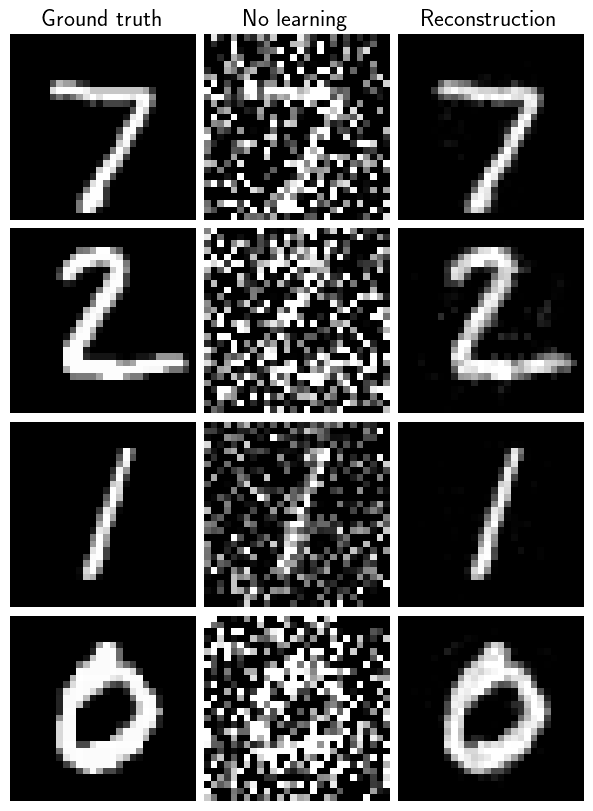

Test results:
PSNR no learning: 3.870 +- 1.864
PSNR: 28.633 +- 6.158


LISTA_CP(
  (iters): ModuleList(
    (0-4): 5 x LISTA_CP_block(
      (W): Linear(in_features=157, out_features=784, bias=False)
      (physics): CompressedSensing(
        (noise_model): ZeroNoise()
      )
    )
  )
)

In [35]:
lista_cp = train_lista(LISTA_CP,5, 5e-4, 5e-3, 30, 30)
lista_cp.eval()

# ALISTA
Now, we set up ALISTA algorithm. For this, we need to find a matrix $W$ minimizing generalized mutual coherence (Definition 8.1.4). We can minimize it exactly or approximately, by minimizing the sum of squares.

In [30]:
# This cell implements the exact minimization. We present W as a linear layer and train it to minimize the loss

class NormConstr(torch.nn.Module):
    r"""
    This class enforces the constraint < W_{i,:}, A_{:,i} > = \|A_{:,i}\|^2 
    In forward, implement an orthogonal projection onto the complement of the above set.
    """
    def __init__(self, A):
        super(NormConstr, self).__init__()
        self.At = A.transpose(0,1)
        self.sqnorms = self.At.norm(dim = 1).square()  
    
    def forward(self, W):
        proj = (W * self.At).sum(dim = 1) 
        proj = proj/ self.sqnorms 
        proj = proj[:,None].repeat(1,self.At.shape[1])
        return self.At * (1 - proj) + W 

def loss_func(out): # coherence
    out = out - torch.diag(torch.diag(out))
    return out.abs().max()

def optimize_mu_exact(num_it):
    print('-------------- FINDING OPTIMAL COHERENT WEIGHT W -------------')
    A = physics._A.clone()
    At = A.transpose(0,1)
    m = A.shape[0]
    n = A.shape[1]

    W_mod = torch.nn.Linear(m, n, bias = False, device = device)
    W_mod.weight.data = A.transpose(0,1).clone()
    torch.nn.utils.parametrize.register_parametrization(W_mod, "weight", NormConstr(A))
    W_mod.train()
    sqnorms = A.norm(dim = 0).square()  
    lr = 0.001 / sqnorms.max().item()
    

    
    out = W_mod(At)
    loss = loss_func(out)
    best_loss = loss.clone().item()
    best_W = W_mod.weight.data.clone().detach()
    epochs = num_it
    
    for it in range(epochs):
        if it % 10000 == 0:
            optimizer = torch.optim.SGD(W_mod.parameters(), lr=lr, momentum = 0.9,  nesterov = True)
            lr = lr * 0.98
            
        out = W_mod(At)
        loss = loss_func(out)
        
        # Backpropagation
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
        if it % 1000 == 0:
            print('Epoch:', it, 'Loss: ', loss.item())
            
        if loss.item() < best_loss:
            best_loss = loss.detach().item()
            best_W = W_mod.weight.data.clone().detach()
    
    
    print('Coherence reached: ', best_loss)
    return best_W


def optimize_mu_inexact(num_it):
    print('-------------- FINDING RELAXED COHERENT WEIGHT W -------------')
    A = physics._A.clone()
    At = A.transpose(0,1)
    m = A.shape[0]
    n = A.shape[1]

    W_mod = A.transpose(0,1).clone()
    sqnorms = A.norm(dim = 0).square()  
    lr = 0.1 / sqnorms.max().item()
    
    def loss_func(out):
        out = out - torch.diag(torch.diag(out))
        # return out.norm().square() 
        return out.abs().max() # return actual coherence
    
    def proj(W,At):
        sqnorms = At.norm(dim = 1).square()  
        proj = (W * At).sum(dim = 1) 
        proj = proj/ sqnorms 
        proj = proj[:,None].repeat(1,At.shape[1])
        return At * (1 - proj) + W 
        
    out = W_mod.matmul(A)
    loss = loss_func(out)
    best_loss = loss.clone().item()
    best_W = W_mod.clone().detach()
    epochs = num_it
    
    for it in range(epochs):
        if it % 10000 == 0:
            lr = lr * 0.98
            
        out = W_mod.matmul(A)
        out = out - torch.diag(torch.diag(out))
        grad =  out.matmul(At)
        
        W_mod = W_mod - lr * grad 
        W_mod = proj(W_mod,At)
        
        loss = loss_func(out)
        
        if it % 1000 == 0:
            print('Epoch:', it, 'Loss: ', loss.item())
            
        if loss.item() < best_loss:
            best_loss = loss.detach().item()
            best_W = W_mod.clone().detach()
            
    print('Coherence reached: ', best_loss)
    return best_W

In [32]:
exact_minimization = True

if exact_minimization:
    best_W = optimize_mu_exact(10**5)
else:
    best_W = optimize_mu_inexact(10**4)

-------------- FINDING OPTIMAL COHERENT WEIGHT W -------------
Epoch: 0 Loss:  0.4021800756454468
Epoch: 1000 Loss:  0.28498053550720215
Epoch: 2000 Loss:  0.2692885994911194
Epoch: 3000 Loss:  0.26013725996017456
Epoch: 4000 Loss:  0.2537824809551239
Epoch: 5000 Loss:  0.24879688024520874
Epoch: 6000 Loss:  0.24461153149604797
Epoch: 7000 Loss:  0.24104157090187073
Epoch: 8000 Loss:  0.23808926343917847
Epoch: 9000 Loss:  0.23536662757396698
Epoch: 10000 Loss:  0.23300960659980774
Epoch: 11000 Loss:  0.23088279366493225
Epoch: 12000 Loss:  0.2289060652256012
Epoch: 13000 Loss:  0.22706785798072815
Epoch: 14000 Loss:  0.22543039917945862
Epoch: 15000 Loss:  0.2237643450498581
Epoch: 16000 Loss:  0.22234204411506653
Epoch: 17000 Loss:  0.2209576666355133
Epoch: 18000 Loss:  0.21965080499649048
Epoch: 19000 Loss:  0.21838915348052979
Epoch: 20000 Loss:  0.21726872026920319
Epoch: 21000 Loss:  0.21604886651039124
Epoch: 22000 Loss:  0.21501660346984863
Epoch: 23000 Loss:  0.21399964392185

In [16]:
class ALISTA_block(torch.nn.Module):
    def __init__(
        self,
        img_size,
        m,
        W,
        spec_norm,
        device,
        alpha = 1.0,
    ):
        super(ALISTA_block, self).__init__()

        self.n = img_size**2
        self.m = m

        nu = 1 / spec_norm**2
        # nu = 1.0
        self.W = torch.nn.Linear(self.m, self.n, bias = False, device = device)
        self.W.weight.data = W.clone()
        self.W.requires_grad_(False)
        self.gamma = torch.nn.Parameter(nu * torch.ones([1]).to(device))
        self.gamma.requires_grad_(True)
        self.soft = torch.nn.Parameter(alpha * nu * torch.ones([1]).to(device))
        self.soft.requires_grad_(True)
        
        self.physics = physics
        self.device = device
        
    def forward(self, x: torch.Tensor, y: torch.Tensor,
                **kwarg) -> torch.Tensor:
        r"""
        Calculate potential function of the FoE.

        :param torch.Tensor x: Input tensor of shape ``(B, C, H, W)``.
        """
        # Apply stacked convolution layers
        z = self.physics(x)
        z = z.add(-y)
        z = self.gamma * self.W(z)
        z = x.add(-z)

        # Soft thresholding
        signz = z.sign()
        z = z.abs() - self.soft
        z = torch.nn.functional.relu(z)
        z = signz * z
        
        return z

class ALISTA(LISTA):
    def __init__(
        self,
        img_size,
        m,
        A,
        spec_norm,
        device,
        alpha = 1.0,
    ):
        super(ALISTA, self).__init__(img_size,
        m,
        A,
        spec_norm,
        device,
        alpha)

        self.W = best_W.clone()
        
    def add_block(self):
        self.iters.append(ALISTA_block(self.img_size, self.m, self.W, self.spec_norm, self.device, self.alpha))

-------------------------------------------------
----------TRAINING  1  BLOCK-------------------
-------------------------------------------------
--------Train perf. pre training----------


/homes/numerik/melnyk/scratch/anaconda3_new/lib/python3.13/site-packages/deepinv/training/trainer.py:1544: UserWarning: non_blocking_transfers=True but DataLoader.pin_memory=False; set pin_memory=True to overlap host-device copies with compute.
  self.setup_train(train=False)


Eval epoch 0: PSNR=9.979, PSNR no learning=2.863
Test results:
PSNR no learning: 2.863 +- 1.719
PSNR: 9.979 +- 1.565
The model has 2 trainable parameters


/homes/numerik/melnyk/scratch/anaconda3_new/lib/python3.13/site-packages/deepinv/training/trainer.py:1352: UserWarning: non_blocking_transfers=True but DataLoader.pin_memory=False; set pin_memory=True to overlap host-device copies with compute.
  self.setup_train()


Train epoch 0: TotalLoss=0.094, PSNR=10.54
Eval epoch 0: PSNR=10.984, PSNR no learning=3.317
Best model saved at epoch 1
Train epoch 1: TotalLoss=0.094, PSNR=10.55
Eval epoch 1: PSNR=10.994, PSNR no learning=3.317
Best model saved at epoch 2
Train epoch 2: TotalLoss=0.094, PSNR=10.549
Eval epoch 2: PSNR=10.99, PSNR no learning=3.317
Train epoch 3: TotalLoss=0.094, PSNR=10.55
Eval epoch 3: PSNR=10.991, PSNR no learning=3.317
Train epoch 4: TotalLoss=0.094, PSNR=10.548
Eval epoch 4: PSNR=10.995, PSNR no learning=3.317
Best model saved at epoch 5
Model, optimizer, scheduler, epoch_start successfully loaded from checkpoint: ckpts/compressed_sensing/26-02-10-09:57:25/26-02-10-09:57:25/ckp_best.pth.tar
--------Train perf. post training----------
Eval epoch 0: PSNR=10.551, PSNR no learning=2.863
Test results:
PSNR no learning: 2.863 +- 1.719
PSNR: 10.551 +- 1.635
--------Val perf. post training----------
Eval epoch 0: PSNR=10.995, PSNR no learning=3.317
Test results:
PSNR no learning: 3.317 +

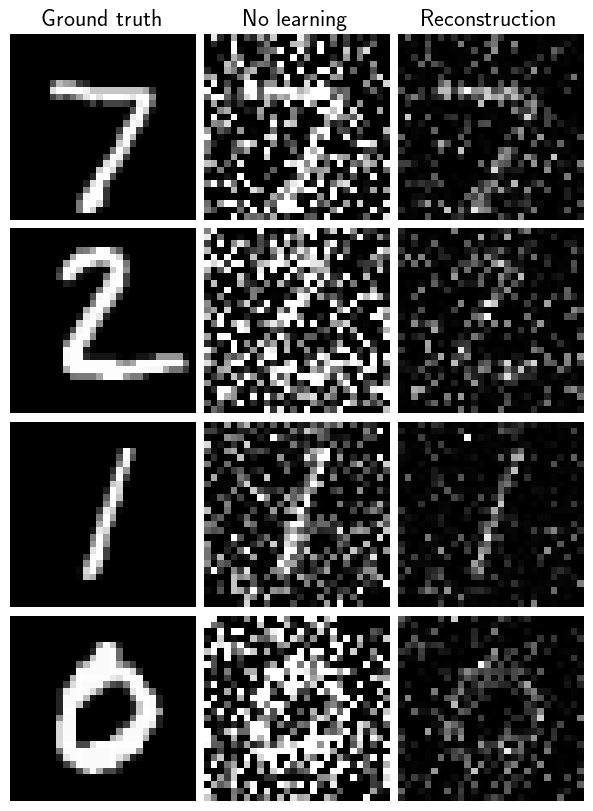

Test results:
PSNR no learning: 3.870 +- 1.864
PSNR: 11.817 +- 1.855


ALISTA(
  (iters): ModuleList(
    (0-19): 20 x ALISTA_block(
      (W): Linear(in_features=157, out_features=784, bias=False)
      (physics): CompressedSensing(
        (noise_model): ZeroNoise()
      )
    )
  )
)

In [17]:
alista = train_lista(ALISTA,20, 1e-1, 1e-1, 5, 5)
alista.eval()

# Why doesn't it train well?
Let's check condition on sparsity from Theorem 8.1.6.

In [22]:
out = best_W.matmul(physics._A)
coherence = loss_func(out)

print('Maximal theoretically allowed sparsity: ', 0.5 + 0.5/coherence.item())

# Possible cure: more measurements and a sparser dataset

Maximal theoretically allowed sparsity:  3.2456814417186823


# Plot an example of reconstruction

In [36]:
from deepinv.utils.plotting import plot_inset, plot

def show_image_comparison(images, suptitle=None, ref=None):
    """Display various images restoration with PSNR and zoom-in"""

    titles = list(images.keys())
    if "Original" in images or ref is not None:
        # If the original image is in the dict, add PSNR in the titles.
        image = images["Original"] if "Original" in images else ref
        psnr = [dinv.metric.cal_psnr(image, im).item() for im in images.values()]
        titles = [
            f"{name} \n (PSNR: {psnr:.2f})" if name != "Original" else name
            for name, psnr in zip(images.keys(), psnr)
        ]
    # Plot the images with zoom-in
    fig = plot_inset(
        list(images.values()),
        titles=titles,
        extract_size=0.2,
        extract_loc=(0.5, 0.0),
        inset_size=0.5,
        return_fig=True,
        show=False,
        figsize=(len(images) * 1.5, 2.5),
    )

    # Add a suptitle if it is provided
    if suptitle:
        plt.suptitle(suptitle, size=12)
        plt.tight_layout()
        fig.subplots_adjust(top=0.85, bottom=0.02, left=0.02, right=0.95)
        plt.show()

# Set up FISTA Solver for comparison


In [37]:
from deepinv.utils.plotting import plot_inset, plot

def show_image_comparison(images, suptitle=None, ref=None):
    """Display various images restoration with PSNR and zoom-in"""

    titles = list(images.keys())
    if "Original" in images or ref is not None:
        # If the original image is in the dict, add PSNR in the titles.
        image = images["Original"] if "Original" in images else ref
        psnr = [dinv.metric.cal_psnr(image, im).item() for im in images.values()]
        titles = [
            f"{name} \n (PSNR: {psnr:.2f})" if name != "Original" else name
            for name, psnr in zip(images.keys(), psnr)
        ]
    # # Plot the images with zoom-in
    fig = plot(
        list(images.values()),
        titles=titles,
        # extract_size=0.2,
        # extract_loc=(0.5, 0.0),
        # inset_size=0.5,
        return_fig=True,
        show=False,
        figsize=(len(images) * 1.5, 2.5),
    )

    # Add a suptitle if it is provided
    if suptitle:
        plt.suptitle(suptitle, size=12)
        plt.tight_layout()
        fig.subplots_adjust(top=0.85, bottom=0.02, left=0.02, right=0.95)
        plt.show()

In [38]:
prior = dinv.optim.L1Prior()

# Algorithm parameters
stepsize = 1.0 / spec_norm.item()**2
lambda_reg = 1e-1
max_iter = 10000
early_stop = True

params_algo = {
                "stepsize": stepsize,
                "lambda": lambda_reg,
                "a": 3,
                # "beta": 1.0,
                }
# print(len(params_algo))

fista = dinv.optim.optim_builder(
    iteration = "FISTA",
    prior=prior,
    data_fidelity=dinv.optim.L2(),
    params_algo=params_algo,
    early_stop=early_stop,
    max_iter=max_iter,
    verbose=False,
)

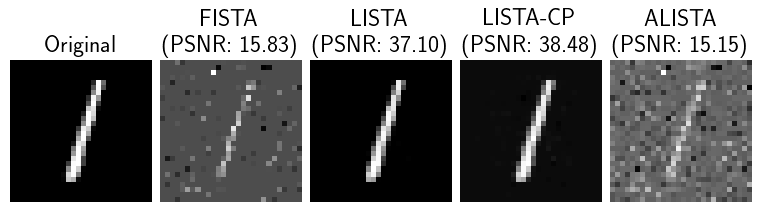

In [39]:
x = test_dataset[2][0].to(device)
x = x[None, :]
y = test_dataset[2][1].to(device)
y = y[None, :]

sparse_recovery_results = {
    "Original": x,
    "FISTA": fista(y,physics),
    "LISTA": lista(y,physics),
    "LISTA-CP": lista_cp(y,physics),
    "ALISTA": alista(y,physics)
}
show_image_comparison(sparse_recovery_results)